# Khmer Handwriting Recognition 

## Evaluate vs Classical

In [1]:
import base64
import csv
import importlib
import io
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from pennylane import numpy as pnp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

BACKEND_DIR = Path("../../website/backend").resolve()
sys.path.insert(0, str(BACKEND_DIR))
import inference as backend  # noqa: E402
importlib.reload(backend)

from plotting import khmer_font_prop  # noqa: E402

READY_DIR = Path("../../data/3_ready/cnn_alphabet")
TRAINING_TABLES_DIR = Path("../../results/tables/training")
CONFUSION_TABLES_DIR = Path("../../results/tables/confusion_matrix")
CONFUSION_CHARTS_DIR = Path("../../results/charts/confusion_matrix")
ACCURACY_TABLES_DIR = Path("../../results/tables/accuracy")
ACCURACY_CHARTS_DIR = Path("../../results/charts/accuracy")
REAL_HANDWRITING_TABLES_DIR = Path("../../results/tables/real_handwriting")
for d in [CONFUSION_TABLES_DIR, CONFUSION_CHARTS_DIR, ACCURACY_TABLES_DIR, ACCURACY_CHARTS_DIR, REAL_HANDWRITING_TABLES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

QUBIT_SIZES = [4, 6, 8]


def to_data_url(png_bytes):
    return "data:image/png;base64," + base64.b64encode(png_bytes).decode("ascii")


def load_qubit_data(n_qubits):
    data = np.load(READY_DIR / f"input_alphabet_{n_qubits}_qubits.npz")
    return (
        pnp.array(data["train_features"]), data["train_labels"],
        pnp.array(data["val_features"]), data["val_labels"],
        pnp.array(data["test_features"]), data["test_labels"],
    )


# A Khmer-capable font, applied only to the specific labels that need it (not globally --
# most Khmer-only fonts have no Latin glyphs, which would break plain-English chart text).
khmer_prop = khmer_font_prop()

SYNTH_DIR = Path("../../data/synthetic_alphabet")
df = pd.read_parquet(SYNTH_DIR / "dataset.parquet")
test_df = df[df["split"] == "test"].reset_index(drop=True)
print(f"held-out test images available: {len(test_df)}")

held-out test images available: 396


## 1. Accuracy, precision, recall, F1 per character

In [2]:
eval_by_qubits = {}

for n_qubits in QUBIT_SIZES:
    id_to_label = backend.get_label_map(n_qubits)
    if id_to_label is None:
        print(f"{n_qubits}q: no trained model yet, skipping")
        continue

    valid_chars = set(id_to_label.values())
    sub_test = test_df[test_df["text"].isin(valid_chars)].reset_index(drop=True)

    y_true, y_pred_q, y_pred_c, q_conf, c_conf = [], [], [], [], []
    for _, row in sub_test.iterrows():
        result = backend.predict_drawing(to_data_url(row["image"]), n_qubits)
        y_true.append(row["text"])
        y_pred_q.append(result["prediction"])
        y_pred_c.append(result["classical_prediction"])
        q_conf.append(result["confidence"])
        c_conf.append(result["classical_confidence"])

    q_report = classification_report(y_true, y_pred_q, output_dict=True, zero_division=0)
    c_report = classification_report(y_true, y_pred_c, output_dict=True, zero_division=0)

    with open(CONFUSION_TABLES_DIR / f"quantum_classification_report_{n_qubits}q.csv", "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["class", "precision", "recall", "f1-score", "support"])
        for cls, m in q_report.items():
            if cls == "accuracy" or not isinstance(m, dict):
                continue
            writer.writerow([cls, round(m["precision"], 4), round(m["recall"], 4), round(m["f1-score"], 4), int(m["support"])])

    eval_by_qubits[n_qubits] = {
        "y_true": np.array(y_true), "y_pred_q": np.array(y_pred_q), "y_pred_c": np.array(y_pred_c),
        "q_conf": np.array(q_conf), "c_conf": np.array(c_conf),
        "q_report": q_report, "c_report": c_report, "labels": sorted(valid_chars),
    }

    per_class_f1 = {cls: m["f1-score"] for cls, m in q_report.items() if cls not in ("accuracy", "macro avg", "weighted avg")}
    worst5 = sorted(per_class_f1.items(), key=lambda x: x[1])[:5]
    best5 = sorted(per_class_f1.items(), key=lambda x: x[1], reverse=True)[:5]

    print(f"=== {n_qubits} qubits ===")
    print(f"quantum accuracy={q_report['accuracy']:.4f}  macro_f1={q_report['macro avg']['f1-score']:.4f}")
    print("worst 5 classes (f1):", worst5)
    print("best 5 classes (f1):", best5)
    print()

=== 4 qubits ===
quantum accuracy=0.8854  macro_f1=0.8851
worst 5 classes (f1): [('ជ', 0.6956521739130435), ('ក', 0.7619047619047619), ('ត', 0.8148148148148148), ('ឌ', 0.8461538461538461), ('ឃ', 0.8571428571428571)]
best 5 classes (f1): [('ខ', 1.0), ('ង', 0.96), ('ណ', 0.96), ('ញ', 0.9565217391304348), ('ច', 0.9166666666666666)]

=== 6 qubits ===
quantum accuracy=0.8990  macro_f1=0.8973
worst 5 classes (f1): [('ផ', 0.6), ('ធ', 0.7368421052631579), ('ភ', 0.7619047619047619), ('ឆ', 0.7692307692307693), ('ក', 0.8)]
best 5 classes (f1): [('ខ', 1.0), ('ញ', 1.0), ('ណ', 1.0), ('ប', 1.0), ('ព', 1.0)]

=== 8 qubits ===
quantum accuracy=0.9242  macro_f1=0.9231
worst 5 classes (f1): [('ក', 0.7368421052631579), ('ថ', 0.8148148148148148), ('ផ', 0.8181818181818182), ('គ', 0.8571428571428571), ('ឃ', 0.8571428571428571)]
best 5 classes (f1): [('ង', 1.0), ('ឈ', 1.0), ('ញ', 1.0), ('ណ', 1.0), ('ប', 1.0)]



## 2. Confusion matrix

In [4]:
def plot_confusion(n_qubits):
    d = eval_by_qubits[n_qubits]
    labels = d["labels"]
    cm = confusion_matrix(d["y_true"], d["y_pred_q"], labels=labels)

    fig, ax = plt.subplots(figsize=(max(6, len(labels) * 0.35), max(6, len(labels) * 0.35)))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=8, fontproperties=khmer_prop)
    ax.set_yticklabels(labels, fontsize=8, fontproperties=khmer_prop)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"Confusion matrix — {n_qubits} qubits")
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout()
    fig.savefig(CONFUSION_CHARTS_DIR / f"confusion_matrix_{n_qubits}q.png", dpi=150)
    plt.show()

    confusions = []
    for i, true_label in enumerate(labels):
        for j, pred_label in enumerate(labels):
            if i != j and cm[i, j] > 0:
                confusions.append((true_label, pred_label, int(cm[i, j])))
    confusions.sort(key=lambda x: x[2], reverse=True)
    print(f"{n_qubits}q -- top confusions (true -> predicted, count):")
    for true_label, pred_label, count in confusions[:8]:
        print(f"   {true_label} -> {pred_label}: {count}")

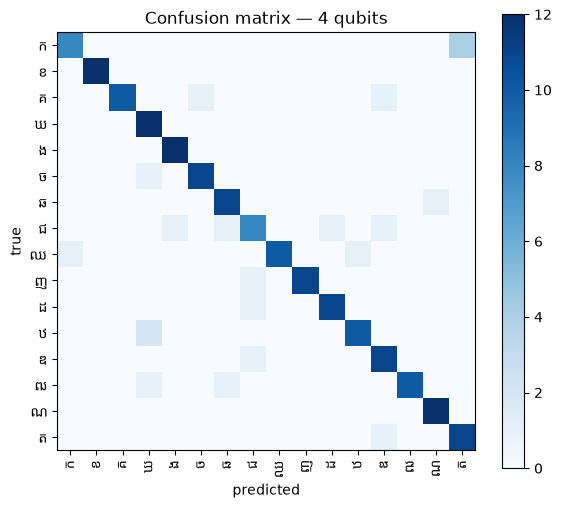

4q -- top confusions (true -> predicted, count):
   ក -> ត: 4
   ឋ -> ឃ: 2
   គ -> ច: 1
   គ -> ឌ: 1
   ច -> ឃ: 1
   ឆ -> ណ: 1
   ជ -> ង: 1
   ជ -> ឆ: 1


In [5]:
plot_confusion(4)

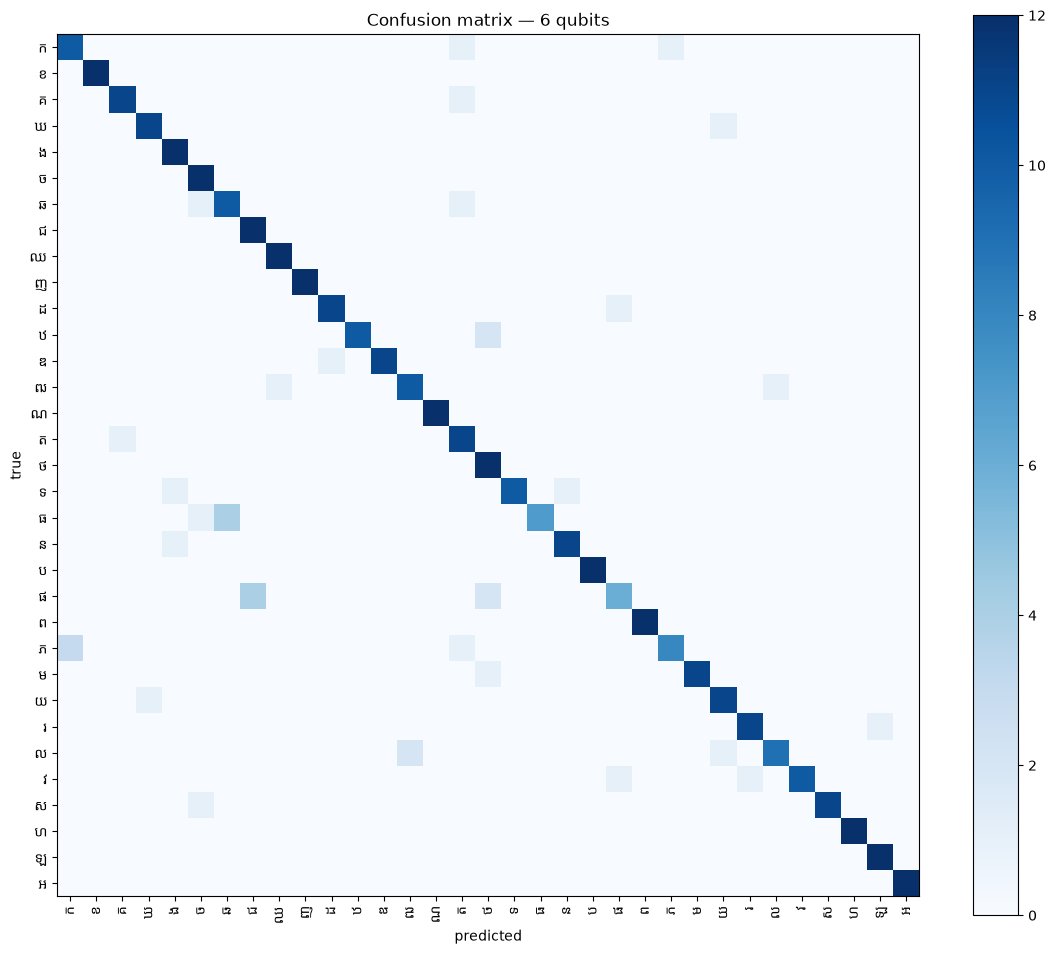

6q -- top confusions (true -> predicted, count):
   ធ -> ឆ: 4
   ផ -> ជ: 4
   ភ -> ក: 3
   ឋ -> ថ: 2
   ផ -> ថ: 2
   ល -> ឍ: 2
   ក -> ត: 1
   ក -> ភ: 1


In [6]:
plot_confusion(6)

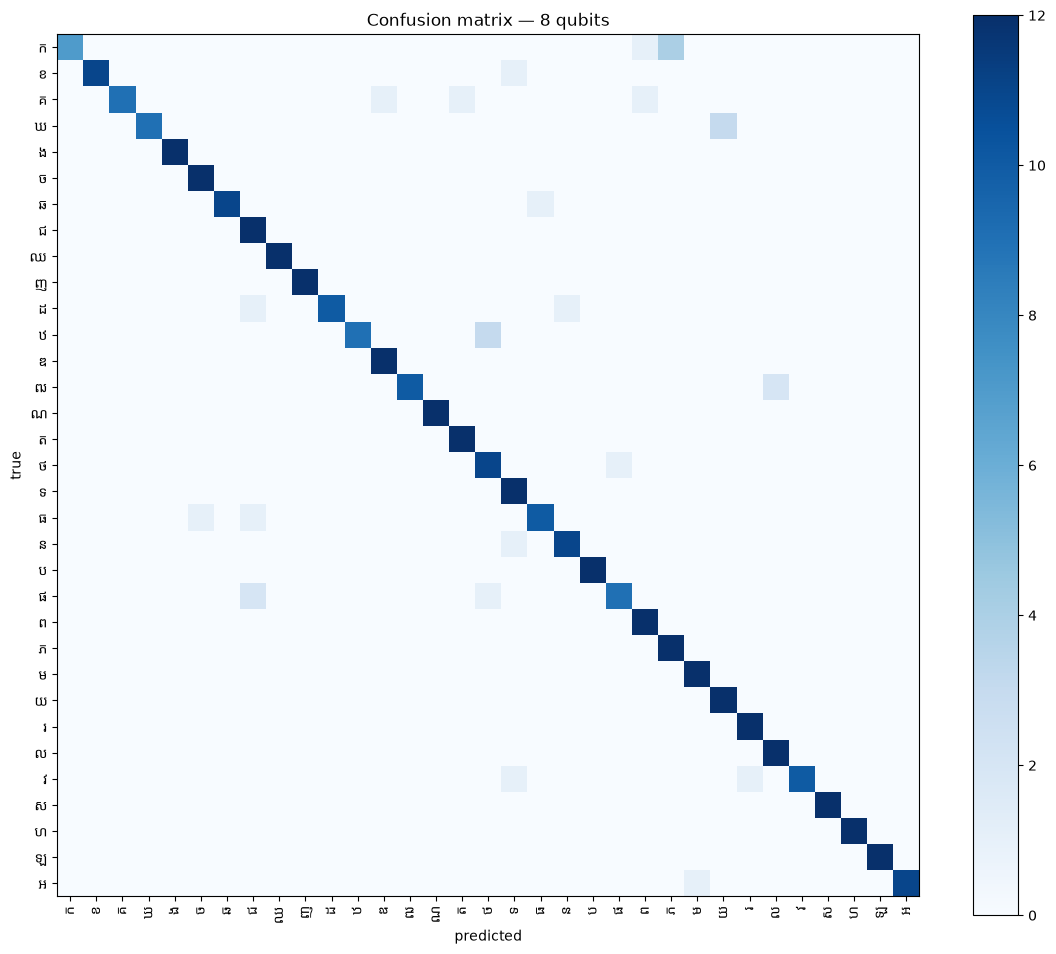

8q -- top confusions (true -> predicted, count):
   ក -> ភ: 4
   ឃ -> យ: 3
   ឋ -> ថ: 3
   ឍ -> ល: 2
   ផ -> ជ: 2
   ក -> ព: 1
   ខ -> ទ: 1
   គ -> ឌ: 1


In [7]:
plot_confusion(8)

## 3. Confidence check: does confidence match actual correctness?

In [8]:
confidence_rows = []
for n_qubits, d in eval_by_qubits.items():
    correct = d["y_true"] == d["y_pred_q"]
    correct_avg = float(np.mean(d["q_conf"][correct])) if correct.any() else float("nan")
    wrong_avg = float(np.mean(d["q_conf"][~correct])) if (~correct).any() else float("nan")
    confidence_rows.append({
        "qubits": n_qubits,
        "accuracy": round(d["q_report"]["accuracy"], 4),
        "correct_avg_confidence": round(correct_avg, 4),
        "wrong_avg_confidence": round(wrong_avg, 4),
        "calibration_gap": round(correct_avg - wrong_avg, 4),
    })

with open(ACCURACY_TABLES_DIR / "quantum_evaluation_summary.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(confidence_rows[0].keys()))
    writer.writeheader()
    writer.writerows(confidence_rows)

pd.DataFrame(confidence_rows)

,qubits,accuracy,correct_avg_confidence,wrong_avg_confidence,calibration_gap
0,4,0.8854,0.9636,0.8043,0.1593
1,6,0.8990,0.9620,0.7490,0.2130
2,8,0.9242,0.9547,0.7915,0.1632


## 4. Test on your own drawings

In [9]:
# 4a. rough hand-stroke sanity check -- no ground truth, just a crash/sanity test
def simple_stroke_drawing(points, size=(300, 120), width=10):
    img = Image.new("L", size, color=255)
    draw = ImageDraw.Draw(img)
    draw.line(points, fill=0, width=width, joint="curve")
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


sample_strokes = [
    [(50, 20), (50, 100), (250, 100), (250, 20)],  # a rough rectangle-ish shape
    [(60, 60), (240, 60)],                          # a single straight stroke
    [(150, 20), (80, 100), (220, 100), (150, 20)],  # a rough triangle
]

for n_qubits in QUBIT_SIZES:
    if backend.get_label_map(n_qubits) is None:
        continue
    for i, pts in enumerate(sample_strokes):
        png = simple_stroke_drawing(pts)
        result = backend.predict_drawing(to_data_url(png), n_qubits)
        print(f"{n_qubits}q stroke#{i}: predicted {result['prediction']!r} "
              f"(confidence {result['confidence']:.2f})")

4q stroke#0: predicted 'ង' (confidence 0.79)
4q stroke#1: predicted 'ញ' (confidence 0.97)
4q stroke#2: predicted 'ច' (confidence 0.85)
6q stroke#0: predicted 'ឈ' (confidence 0.35)
6q stroke#1: predicted 'ន' (confidence 0.88)
6q stroke#2: predicted 'ង' (confidence 0.89)
8q stroke#0: predicted 'ង' (confidence 0.47)
8q stroke#1: predicted 'ខ' (confidence 0.81)
8q stroke#2: predicted 'ណ' (confidence 0.21)


In [10]:
# 4b. real handwriting (the domain-gap test) -- genuine human-written single characters,
# not synthetic font renders
real_df = pd.read_parquet(Path("../../data/2_cleaned/cleaned_data.parquet"))
real_df = real_df[real_df["text"].str.match("^[ក-អឥ-ឳ០-៩]$", na=False)].reset_index(drop=True)
print(f"real handwritten single-glyph images: {len(real_df)} ({real_df['text'].nunique()} characters)")

real_results = []
for n_qubits in QUBIT_SIZES:
    id_to_label = backend.get_label_map(n_qubits)
    if id_to_label is None:
        continue
    sub = real_df[real_df["text"].isin(set(id_to_label.values()))]

    quantum_correct = 0
    classical_correct = 0
    for _, row in sub.iterrows():
        result = backend.predict_drawing(to_data_url(row["image"]["bytes"]), n_qubits)
        quantum_correct += int(result["prediction"] == row["text"])
        classical_correct += int(result["classical_prediction"] == row["text"])
    n = len(sub)
    real_results.append({
        "qubits": n_qubits,
        "n_images": n,
        "n_characters": sub["text"].nunique(),
        "random_guess": round(1 / len(id_to_label), 4),
        "quantum_accuracy": round(quantum_correct / n, 4) if n else float("nan"),
        "classical_accuracy": round(classical_correct / n, 4) if n else float("nan"),
    })
    print(f"{n_qubits}q -> {n} real images: quantum {quantum_correct}/{n}, classical {classical_correct}/{n}")

with open(REAL_HANDWRITING_TABLES_DIR / "real_handwriting_accuracy.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(real_results[0].keys()))
    writer.writeheader()
    writer.writerows(real_results)

print("Wrote:", REAL_HANDWRITING_TABLES_DIR / "real_handwriting_accuracy.csv")
pd.DataFrame(real_results)

real handwritten single-glyph images: 189 (57 characters)
4q -> 40 real images: quantum 21/40, classical 26/40
6q -> 71 real images: quantum 38/71, classical 44/71
8q -> 71 real images: quantum 37/71, classical 44/71
Wrote: ..\..\results\tables\real_handwriting\real_handwriting_accuracy.csv


,qubits,n_images,n_characters,random_guess,quantum_accuracy,classical_accuracy
0,4,40,16,0.0625,0.5250,0.6500
1,6,71,33,0.0303,0.5352,0.6197
2,8,71,33,0.0303,0.5211,0.6197


## 5. Quantum vs classical: table and charts

In [11]:
# 5a. vs the full classical CNN baseline, live predictions on the same test images
comparison_rows = []
for n_qubits, d in eval_by_qubits.items():
    comparison_rows.append({
        "qubits": n_qubits,
        "quantum_accuracy": round(d["q_report"]["accuracy"], 4),
        "classical_cnn_accuracy": round(d["c_report"]["accuracy"], 4),
        "quantum_macro_f1": round(d["q_report"]["macro avg"]["f1-score"], 4),
        "classical_cnn_macro_f1": round(d["c_report"]["macro avg"]["f1-score"], 4),
    })

with open(ACCURACY_TABLES_DIR / "quantum_vs_classical_cnn.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(comparison_rows[0].keys()))
    writer.writeheader()
    writer.writerows(comparison_rows)

pd.DataFrame(comparison_rows)

,qubits,quantum_accuracy,classical_cnn_accuracy,quantum_macro_f1,classical_cnn_macro_f1
0,4,0.8854,0.9427,0.8851,0.7630
1,6,0.8990,0.9318,0.8973,0.9306
2,8,0.9242,0.9318,0.9231,0.9306


In [12]:
# 5b. vs a classical linear layer taking the SAME n_qubits CNN features the quantum
# circuit receives, with no quantum circuit at all -- isolates what entangling those
# features through the quantum circuit adds over just linearly reading them.
ablation_rows = []
for n_qubits in QUBIT_SIZES:
    if n_qubits not in eval_by_qubits:
        continue
    X_train, y_train, X_val, y_val, X_test, y_test = load_qubit_data(n_qubits)

    clf = LogisticRegression(max_iter=2000)
    clf.fit(np.array(X_train), y_train)
    test_acc = accuracy_score(y_test, clf.predict(np.array(X_test)))
    quantum_acc = eval_by_qubits[n_qubits]["q_report"]["accuracy"]

    ablation_rows.append({
        "qubits": n_qubits,
        "quantum_circuit_accuracy": round(quantum_acc, 4),
        "classical_linear_same_input_accuracy": round(float(test_acc), 4),
        "quantum_advantage": round(quantum_acc - float(test_acc), 4),
    })
    print(f"{n_qubits}q: quantum circuit {quantum_acc:.4f} vs classical linear (same input) {test_acc:.4f}")

with open(ACCURACY_TABLES_DIR / "quantum_vs_linear_same_size.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(ablation_rows[0].keys()))
    writer.writeheader()
    writer.writerows(ablation_rows)

pd.DataFrame(ablation_rows)

4q: quantum circuit 0.8854 vs classical linear (same input) 0.9583
6q: quantum circuit 0.8990 vs classical linear (same input) 0.9318
8q: quantum circuit 0.9242 vs classical linear (same input) 0.9444


,qubits,quantum_circuit_accuracy,classical_linear_same_input_accuracy,quantum_advantage
0,4,0.8854,0.9583,-0.0729
1,6,0.8990,0.9318,-0.0328
2,8,0.9242,0.9444,-0.0202


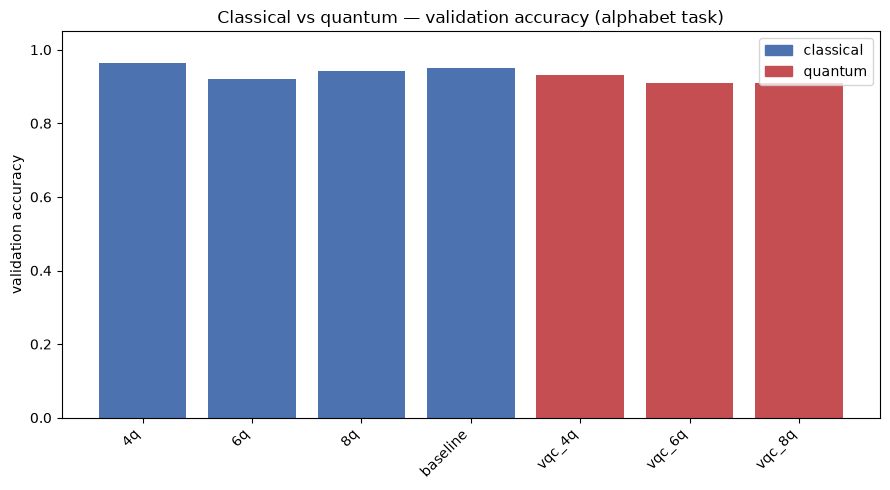

,model_type,model,val_accuracy,test_accuracy
0,classical,4q,0.9635,0.9583
1,classical,6q,0.9192,0.9444
2,classical,8q,0.9419,0.9444
3,classical,baseline,0.9495,0.9318
4,quantum,vqc_4q,0.9323,0.8854
5,quantum,vqc_6q,0.9091,0.8990
6,quantum,vqc_8q,0.9091,0.9242


In [13]:
# 5c. every trained model's validation/test accuracy, from the training summaries
# written by 02_train_hybrid.ipynb and 01_train_cnn.ipynb -- not live predictions,
# the recorded training-time numbers.
classical_df = pd.read_csv(TRAINING_TABLES_DIR / "cnn_alphabet_training_summary.csv")
quantum_summary_df = pd.read_csv(TRAINING_TABLES_DIR / "training_summary_alphabet.csv")
canonical_layers = quantum_summary_df["layers"].max()  # the deployed choice is always the largest swept value
quantum_canonical_df = quantum_summary_df[quantum_summary_df["layers"] == canonical_layers]

rows = []
for _, r in classical_df.iterrows():
    rows.append({"model_type": "classical", "model": r["model"], "val_accuracy": r["best_val_accuracy"], "test_accuracy": r["test_accuracy"]})
for _, r in quantum_canonical_df.iterrows():
    rows.append({"model_type": "quantum", "model": f"vqc_{int(r['qubits'])}q", "val_accuracy": r["best_val_accuracy"], "test_accuracy": r["test_accuracy"]})
comparison_summary_df = pd.DataFrame(rows)
comparison_summary_df.to_csv(ACCURACY_TABLES_DIR / "comparison_summary.csv", index=False)

colors = comparison_summary_df["model_type"].map({"classical": "#4c72b0", "quantum": "#c44e52"})
plt.figure(figsize=(9, 5))
plt.bar(comparison_summary_df["model"], comparison_summary_df["val_accuracy"], color=colors)
plt.ylabel("validation accuracy")
plt.title("Classical vs quantum — validation accuracy (alphabet task)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
handles = [plt.Rectangle((0, 0), 1, 1, color="#4c72b0"), plt.Rectangle((0, 0), 1, 1, color="#c44e52")]
plt.legend(handles, ["classical", "quantum"])
plt.tight_layout()
plt.savefig(ACCURACY_CHARTS_DIR / "accuracy_comparison.png", dpi=150)
plt.show()

comparison_summary_df

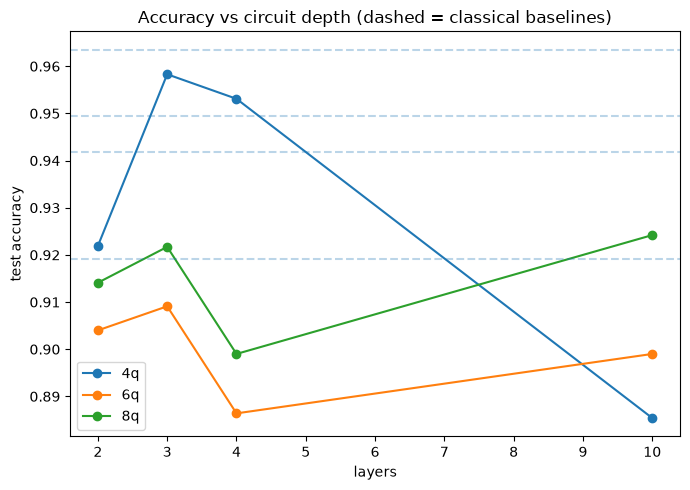

,qubits,layers,n_classes,best_epoch,best_val_accuracy,test_accuracy
0,4,2,16,16,0.9635,0.9219
1,4,3,16,15,0.9479,0.9583
2,4,4,16,28,0.9531,0.9531
3,4,10,16,26,0.9323,0.8854
4,6,2,33,18,0.9040,0.9040
5,6,3,33,28,0.9066,0.9091
6,6,4,33,5,0.8763,0.8864
7,6,10,33,36,0.9091,0.8990
8,8,2,33,31,0.9167,0.9141
9,8,3,33,9,0.9167,0.9217


In [14]:
# 5d. accuracy vs circuit depth, from the full layer sweep 02_train_hybrid.ipynb already
# trained and checkpointed (2, 3, 4, and the deployed 10 layers) -- no retraining here,
# just reading what was already saved.
plt.figure(figsize=(7, 5))
for n_qubits in QUBIT_SIZES:
    rows = quantum_summary_df[quantum_summary_df["qubits"] == n_qubits].sort_values("layers")
    plt.plot(rows["layers"], rows["test_accuracy"], marker="o", label=f"{n_qubits}q")
for _, r in classical_df.iterrows():
    plt.axhline(r["best_val_accuracy"], linestyle="--", alpha=0.3)
plt.xlabel("layers")
plt.ylabel("test accuracy")
plt.title("Accuracy vs circuit depth (dashed = classical baselines)")
plt.legend()
plt.tight_layout()
plt.savefig(ACCURACY_CHARTS_DIR / "layer_sweep.png", dpi=150)
plt.show()

quantum_summary_df.sort_values(["qubits", "layers"])